time-series lake level retrieval from swot raster product
1. define extent of virtual station
2. lake level retrived from swot raster product
3. time-series lake level processing. 


In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
from shapely.geometry import Polygon
import geopandas as gpd
from pathlib import Path
from utils.swot_data_mask import swot_raster_mask
from utils.swot_data_filter import iter_sigma 
import matplotlib.pyplot as plt


In [ ]:
data_dir = 'data/swot/raster/caohai'
lake_vec = 'data/lakes-ygp/caohai_hydrolake_v10.gpkg'
path_save = "data/swot/raster/caohai/result/wse_2023_2026.csv"
swot_raster_files = sorted(Path(data_dir).glob('*.nc'))
print(len(swot_raster_files))  


8


VS extent:  (104.2101428223356, 26.860221629533694, 104.21469184882486, 26.865122037802553)


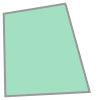

In [12]:
# 1. spatial extent of virtual station (VS)
vs_coords = [
        (104.21022865302407,26.860221629533694),
        (104.21469184882486,26.860451340913542),
        (104.21340438849771,26.865122037802553),
        (104.2101428223356,26.864586065988135),
        (104.21022865302407,26.860221629533694)
            ]

vs_polygon = Polygon(vs_coords)
vs_gdf = gpd.GeoDataFrame(geometry=[vs_polygon], crs="EPSG:4326")
print('VS extent: ', vs_polygon.bounds) 
vs_polygon

In [ ]:
## 2.1 data processing for one swot raster
file_path = swot_raster_files[5]
with xr.open_dataset(file_path) as ds:         
    data_masked = swot_raster_mask(ds, 
                        vars_sel=['x', 'y', 'wse', 'wse_qual'], 
                        region_gdf=vs_gdf,                     
                        path_masked=None)
    valid = (data_masked["wse_qual"] <= 1) & data_masked["wse"].notnull()
    data_masked["wse"] = data_masked["wse"].where(valid) 
    data_filtered = iter_sigma(data_masked["wse"].values, sigma_scale=2)

    print('date:', data_masked.attrs['time_granule_start'])
    print('filtered data mean:', np.nanmean(data_filtered))
    print('filtered data std:', np.nanstd(data_filtered))
    print("filtered valid_count:", np.isfinite(data_filtered).sum().item())


date: 2023-04-06T16:04:22.599308Z
filtered data mean: 2172.1667
filtered data std: 0.061340153
filtered valid_count: 21


In [ ]:
### 2.2 batch processing for swot raster data
results = []
for file_path in swot_raster_files:
    with xr.open_dataset(file_path) as ds: 
        print('processing:', file_path)
        ## (1) spatial subsetting and variables selection.  
        try: 
            data_masked = swot_raster_mask(ds, 
                                vars_sel=['x', 'y', 'wse', 'wse_qual'], 
                                region_gdf=vs_gdf,                     
                                path_masked=None)
        except Exception as e:
            print(f"No data in VS: {file_path}")
            continue

        ## (2) filter valid wse values
        valid = (data_masked["wse_qual"] <= 1) & data_masked["wse"].notnull()
        data_masked["wse"] = data_masked["wse"].where(valid) 
        data_filtered = iter_sigma(data_masked["wse"].values, sigma_scale=2)  ## iteratively remove outliers
        ## (3) calculate statistics for the filtered data
        date = data_masked.attrs['time_granule_start']
        mean = np.nanmean(data_filtered)
        std = np.nanstd(data_filtered)
        num_valid = np.isfinite(data_filtered).sum().item()
        ## TODO: try add vs extent to the data, and save as geopandas data.
        if not np.isnan(mean):
            results.append({
                # 'date': pd.to_datetime(date),
                'date_day': pd.to_datetime(date).strftime("%Y-%m-%d"),
                'wse_mean': mean,
                'wse_std': std,
                'valid_count': num_valid
                })

results_df = pd.DataFrame(results)


processing: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_343_003F_20241124T080613_20241124T080634_PGD0_01.nc
No data in VS: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_343_003F_20241124T080613_20241124T080634_PGD0_01.nc
processing: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_399_004F_20241126T080735_20241126T080755_PGD0_01.nc
No data in VS: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_399_004F_20241126T080735_20241126T080755_PGD0_01.nc
processing: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_562_151F_20241202T044231_20241202T044252_PGD0_01.nc
No data in VS: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_024_562_151F_20241202T044231_20241202T044252_PGD0_01.nc
processing: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_025_287_002F_20241213T044954_20241213T045015_PGD0_01.nc
No data in VS: data/swot/raster/caohai/SWOT_L2_HR_Raster_100m_UTM01C_N_x_x_x_025_

In [15]:
## Select the record with the maximum valid_count for each day
if not results_df.empty:
    idx = results_df.groupby(results_df["date_day"])["valid_count"].idxmax()
    results_df = results_df.loc[idx].sort_values("date_day").reset_index(drop=True)
results_df.head(5)


,date_day,wse_mean,wse_std,valid_count
0,2023-04-06,2172.166748,0.061340,21
1,2023-04-07,2172.148438,0.041625,21
2,2023-04-08,2172.170410,0.070579,26


In [16]:
# Hampel 滤波剔除水位异常值
## TODO: consider temporal window. 
def hampel_filter(df, col="wse_mean", w=7, n_sig=3, tol=0.2):
    # 1. 计算滑动中位数与残差
    med = df[col].rolling(w, center=True, min_periods=1).median()
    diff = (df[col] - med).abs()
    # 2. 计算 MAD 并设定阈值
    mad = 1.4826 * diff.rolling(w, center=True, min_periods=1).median()
    thresh = (n_sig * mad).clip(lower=tol)
    # 3. 过滤并返回
    return df[diff <= thresh].reset_index(drop=True)

results_filter_df = hampel_filter(results_df)
results_filter_df.head()

,date_day,wse_mean,wse_std,valid_count
0,2023-04-06,2172.166748,0.061340,21
1,2023-04-07,2172.148438,0.041625,21
2,2023-04-08,2172.170410,0.070579,26


Text(0, 0.5, 'Water Level (m)')

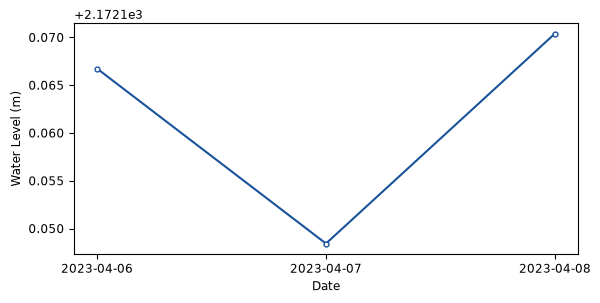

In [17]:
## plot time-series data 
plt.rcParams['font.size'] = 8.5
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.plot(results_filter_df['date_day'], 
        results_filter_df['wse_mean'], 
        color='#1a539b', marker='o', ms=3.5, mfc='white')
ax.set_xlabel('Date')
ax.set_ylabel('Water Level (m)')


In [18]:
## write out
# results_filter_df.to_csv(path_save, index=False)
